In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.read_csv(RAIZ / "data" / "raw" / "ai4i2020.csv")
df.shape

(10000, 14)

In [10]:
print("Filas completas duplicadas:", df.duplicated().sum())
print("UDI repetidos:", df["UDI"].duplicated().sum())
print("\nNulos por columna:")
print(df.isna().sum())
df.describe().T

Filas completas duplicadas: 0
UDI repetidos: 0

Nulos por columna:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [3]:
modos = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print("Type coincide con la 1.ª letra de Product ID:", (df["Type"] == df["Product ID"].str[0]).all())

falla_calculada = (df[modos].sum(axis=1) > 0).astype(int)
inconsistentes = df[falla_calculada != df["Machine failure"]]
print("Filas donde 'Machine failure' no coincide con los 5 modos:", len(inconsistentes))
inconsistentes[["UDI", "Machine failure"] + modos].head(10)

Type coincide con la 1.ª letra de Product ID: True
Filas donde 'Machine failure' no coincide con los 5 modos: 27


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


In [4]:
df.groupby("Type")["Machine failure"].agg(filas="count", fallas="sum", tasa="mean").round(4)

,filas,fallas,tasa
Type,,,
H,1003,21,0.0209
L,6000,235,0.0392
M,2997,83,0.0277


In [5]:
sin_modo = ((df["Machine failure"] == 1) & (df[modos].sum(axis=1) == 0)).sum()
rnf_sin_falla = ((df["RNF"] == 1) & (df["Machine failure"] == 0)).sum()
print("Falla sin ningún modo activo:", sin_modo)
print("RNF = 1 pero Machine failure = 0:", rnf_sin_falla)
print("Total inconsistentes:", len(inconsistentes))

Falla sin ningún modo activo: 9
RNF = 1 pero Machine failure = 0: 18
Total inconsistentes: 27


In [6]:
numericas = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
resumen = []
for col in numericas:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < inf) | (df[col] > sup)).sum()
    resumen.append({"variable": col, "limite_inf": round(inf, 1), "limite_sup": round(sup, 1),
                    "outliers": n, "porcentaje": round(100 * n / len(df), 2)})
pd.DataFrame(resumen)

,variable,limite_inf,limite_sup,outliers,porcentaje
0,Air temperature [K],293.5,306.3,0,0.00
1,Process temperature [K],305.4,314.6,0,0.00
2,Rotational speed [rpm],1139.5,1895.5,418,4.18
3,Torque [Nm],12.8,67.2,69,0.69
4,Tool wear [min],-110.5,325.5,0,0.00


In [7]:
for col in ["Rotational speed [rpm]", "Torque [Nm]"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    es_outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    print(col)
    print(df.groupby(es_outlier)["Machine failure"].agg(filas="count", fallas="sum", tasa="mean").round(4), "\n")

Rotational speed [rpm]
                        filas  fallas    tasa
Rotational speed [rpm]                       
False                    9582     304  0.0317
True                      418      35  0.0837 

Torque [Nm]
             filas  fallas    tasa
Torque [Nm]                       
False         9931     277  0.0279
True            69      62  0.8986 



In [12]:
for col in ["Rotational speed [rpm]", "Torque [Nm]"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    es_outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    print(col)
    print(df.groupby(es_outlier)["Machine failure"].agg(filas="count", fallas="sum", tasa="mean").round(4), "\n")

Rotational speed [rpm]
                        filas  fallas    tasa
Rotational speed [rpm]                       
False                    9582     304  0.0317
True                      418      35  0.0837 

Torque [Nm]
             filas  fallas    tasa
Torque [Nm]                       
False         9931     277  0.0279
True            69      62  0.8986 



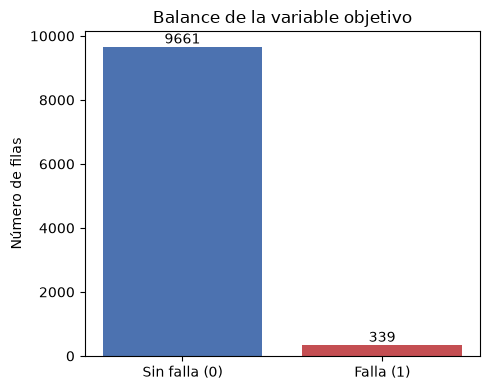

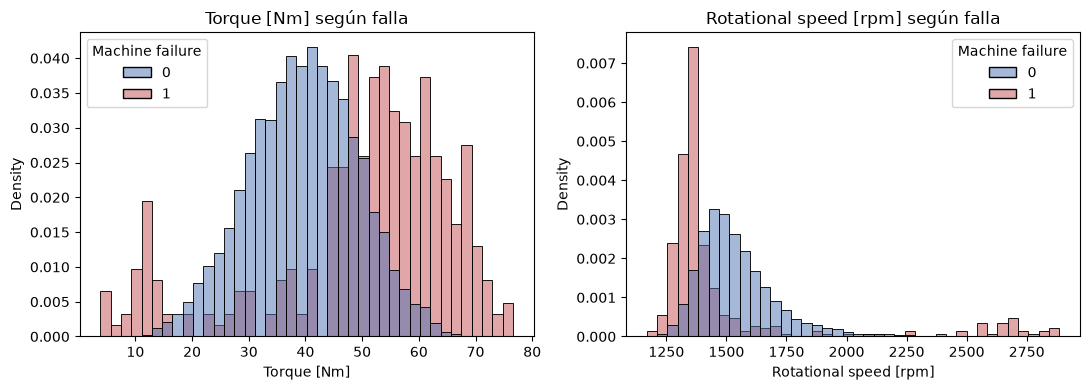

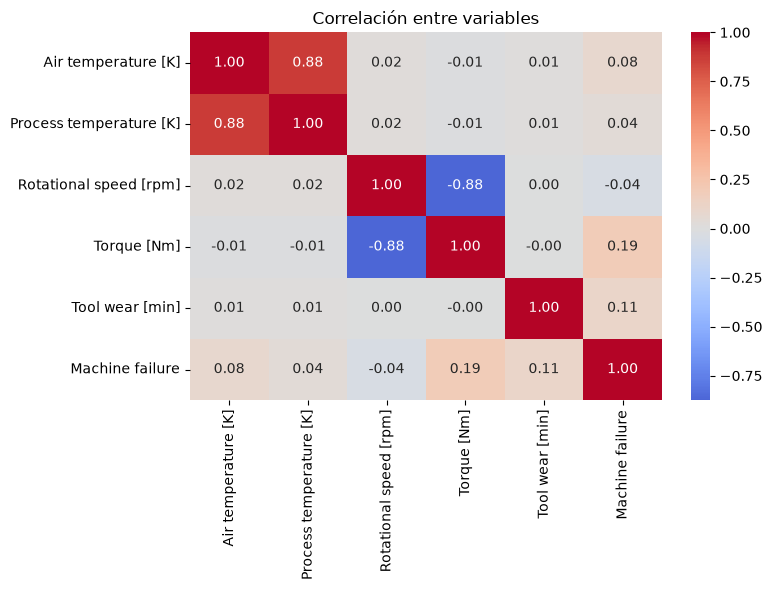

In [15]:
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
colores = {0: "#4C72B0", 1: "#C44E52"}

# Gráfico 1: balance de la variable objetivo
conteo = df["Machine failure"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(["Sin falla (0)", "Falla (1)"], conteo.values, color=[colores[0], colores[1]])
ax.bar_label(barras)
ax.set_title("Balance de la variable objetivo")
ax.set_ylabel("Número de filas")
plt.tight_layout()
plt.savefig(FIG / "1_balance_clases.png", dpi=150)
plt.show()

# Gráficos 2 y 3: torque y velocidad según haya falla o no
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(ejes, ["Torque [Nm]", "Rotational speed [rpm]"]):
    sns.histplot(data=df, x=col, hue="Machine failure", bins=40, stat="density",
                 common_norm=False, palette=colores, ax=ax)
    ax.set_title(f"{col} según falla")
plt.tight_layout()
plt.savefig(FIG / "2_3_torque_velocidad_por_falla.png", dpi=150)
plt.show()

# Gráfico 4: correlaciones
cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
        "Torque [Nm]", "Tool wear [min]", "Machine failure"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables")
plt.tight_layout()
plt.savefig(FIG / "4_correlaciones.png", dpi=150)
plt.show()

In [16]:
clean = df.rename(columns={
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temp_k",
    "Process temperature [K]": "process_temp_k",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "tool_wear_min",
    "Machine failure": "machine_failure",
    "TWF": "twf", "HDF": "hdf", "PWF": "pwf", "OSF": "osf", "RNF": "rnf",
})

# Marca las filas inconsistentes (no se borran, solo se señalan)
clean["etiqueta_inconsistente"] = (falla_calculada != df["Machine failure"]).astype(int).values

CLEAN = RAIZ / "data" / "clean"
CLEAN.mkdir(parents=True, exist_ok=True)
clean.to_csv(CLEAN / "ai4i2020_clean.csv", index=False)

print(clean.shape)
print(clean.dtypes)
print("Filas inconsistentes marcadas:", clean["etiqueta_inconsistente"].sum())

(10000, 15)
udi                         int64
product_id                    str
type                          str
air_temp_k                float64
process_temp_k            float64
rpm                         int64
torque_nm                 float64
tool_wear_min               int64
machine_failure             int64
twf                         int64
hdf                         int64
pwf                         int64
osf                         int64
rnf                         int64
etiqueta_inconsistente      int64
dtype: object
Filas inconsistentes marcadas: 27
